# OOI Arrays: Overview and Context for CHLA Profiling
**Author:** Eli Holmes (NOAA)</br>
Last updated: Nov 21, 2026

The [Ocean Observatories Initiative (OOI)](https://oceanobservatories.org/) is a long-term, NSF-funded ocean observing program designed to provide continuous, high-resolution measurements across key regions of the global and coastal ocean.  
OOI systems collect physical, chemical, biological, and geological observations using a combination of:

- **Moorings: fixed location** (surface, mid-water, deep-water) — These are sensors at fixed discrete depths. CHLA is available only at those specific depths.

- **Depth Profiler systems: fixed location**  
  - **Wire-following profilers (WFPs)** — Provide high-resolution vertical depth profiles, sampling repeatedly up and down the water column.  
  - **Shallow profilers (SPs)** — Motorized profilers delivering dense CHLA depth profiles in the 0-200m range, often with higher sampling frequency than WFPs.  
  - **Deep profilers (DPs)** — Provide deep water (> 200m) vertical profiles.

- **Autonomous gliders: moving location** — Mobile platforms that execute repeated sawtooth depth profiles and produce full vertical CHLA measurements for each dive.

Across these platforms, OOI instruments collect high-frequency, vertically resolved biological measurements, including:
chlorophyll-a concentration, particulate organic matter & phytoplankton biomass, colored dissolved organic matter (CDOM), photosynthetically available radiation (PAR), sea water physical properties (temperature, salinity, and density), dissolved oxygen, nitrate, pH, pCO₂.  We are interested in modeling CHLA vertical depth profiles and will focus on the chlorophyll-a concentration measurement. OOI data is openly available through the OOI Data Portal and ERDDAP servers.


![](../../../assets/ooi.jpg)



## OOI Regional Arrays

OOI consists of **two major coastal arrays**, a **regional cabled array**, and **four global open-ocean arrays**. Coastal arrays sample continental shelf, slope, and upwelling environments that exhibit strong seasonal biological and physical variability. These sites typically include vertically profiling platforms that provide **full or partial CHLA depth profiles** in the upper 0–200 m. Global Arrays observe key climate-relevant open-ocean regions and generally **do not include vertical profilers**, but they do provide **CHLA at fixed depths** within the 0–200 m zone, which can still be mapped into depth bins.

1. **Coastal Stations:**
    - **Endurance Array (Oregon & Washington)** — Samples an eastern boundary upwelling system across nearshore, shelf, and offshore environments. Platforms include surface and subsurface moorings (fixed-depth CHLA), **wire-following profilers** (0–200 m), **cabled shallow/deep profilers**, and autonomous gliders (0–200+ m profiles).
    - **Pioneer Array (Northwest Atlantic / Mid-Atlantic Bight)** — Observes cross-shelf and shelf-break frontal systems with strong biological gradients. Platforms include multi-tier moorings, surface buoys, gliders, and (in most years) **shallow profilers** that provided high-resolution 0–200 m CHLA profiles.
    - **Regional Cabled Array (Washington–Oregon offshore)** — Provides real-time power and data to offshore slope and deepwater nodes. Only the **cabled shallow profilers** contribute 0–200 m CHLA profiles; most deep or seafloor instruments do not sample CHLA.

2. **Global Stations:**
    - **Papa Array (Gulf of Alaska)** — Subarctic gyre; CHLA sensors at fixed depths (typically 7–50 m).
    - **Irminger Sea Array (Greenland–Iceland region)** — High-latitude convection region; CHLA at fixed depths in the upper 100 m.
    - **Argentine Basin Array (Southwest Atlantic)** — Deep-ocean circulation site; limited CHLA at one or two fixed depths (~30 m).
    - **Southern Ocean Array (South of Tasmania)** — High-mixing Southern Ocean environment; CHLA measurements at fixed depths in the upper 50 m.

## Workflow

This notebook processes CHLA data from OOI platforms showing:

- automated ERDDAP retrieval,  
- daily depth-binned CHLA profiles,  
- merged datasets across platforms and regions.

We work with a set of Endurance platforms listed in `endurance_dict`, including:

- **Offshore and shelf surface moorings** (near-surface instrument frames with fluorometers)
- **Cabled shallow and deep profilers**
- **Wire-following profilers** on offshore moorings
- **Inshore and shelf surface-piercing profilers**

For each platform, we:

1. Request CHLA data from the OOI ERDDAP server.
2. Process the data into **daily mean CHLA profiles** in fixed 10 m depth bins between 0 and 200 m.
3. Save per-platform parquet files and then merge them into a single, combined Endurance dataset.
4. Plot example CHLA–depth profiles for individual daily "profiles" (platform × day).


## Inspect ERDDAP variables for a single instrument

First, inspect the available variables for one representative dataset on the OOI ERDDAP server.  
This helps confirm the exact variable names for chlorophyll-a and related quality-control flags before building generalized code.


In [1]:
# See the variables
import pandas as pd
base = "https://erddap.dataexplorer.oceanobservatories.org/erddap/tabledap"
dataset_id = "ooi-ce04osps-sf01b-3a-flortd104"
header_url = f"{base}/{dataset_id}.csv?"
# read only the header, skip the units row
df0 = pd.read_csv(header_url, skiprows=[1], nrows=0)
print(df0.columns)

Index(['time', 'latitude', 'longitude', 'z',
       'concentration_of_colored_dissolved_organic_matter_in_sea_water_expressed_as_equivalent_mass_fraction_of_quinine_sulfate_dihydrate_profiler_depth_enabled',
       'concentration_of_colored_dissolved_organic_matter_in_sea_water_expressed_as_equivalent_mass_fraction_of_quinine_sulfate_dihydrate_profiler_depth_enabled_qc_agg',
       'concentration_of_colored_dissolved_organic_matter_in_sea_water_expressed_as_equivalent_mass_fraction_of_quinine_sulfate_dihydrate_profiler_depth_enabled_qc_tests',
       'mass_concentration_of_chlorophyll_a_in_sea_water_profiler_depth_enabled',
       'mass_concentration_of_chlorophyll_a_in_sea_water_profiler_depth_enabled_qc_agg',
       'mass_concentration_of_chlorophyll_a_in_sea_water_profiler_depth_enabled_qc_tests',
       'depth_reading_profiler_depth_enabled',
       'depth_reading_profiler_depth_enabled_qc_agg',
       'depth_reading_profiler_depth_enabled_qc_tests',
       'flubsct_profiler_depth_

## Prototype daily CHLA binning and profile plotting for one mooring

Here we prototype the workflow for **one Endurance instrument**:

- Request time series from ERDDAP.
- Convert depth from `z` (altitude, negative down) to positive meters.
- Filter to the 0–200 m range.
- Bin CHLA into 10 m depth bins (0–10, 10–20, …, 190–200 m).
- Aggregate to daily means per depth bin.
- Pick one daily profile and plot **CHLA vs depth**.


In [2]:
# See a dataframe with the variables we want
import pandas as pd
import os
import numpy as np
dataset_id = "ooi-ce04osps-sf01b-3a-flortd104"
chl_var = "mass_concentration_of_chlorophyll_a_in_sea_water_profiler_depth_enabled"
url = (
    "https://erddap.dataexplorer.oceanobservatories.org/erddap/tabledap/"
    f"{dataset_id}.csv?"
    "time%2Clatitude%2Clongitude%2Cz%2C"
    f"{chl_var}%2C"
    f"{chl_var}_qc_agg"
    "&time%3E=2024-03-01"
    "&time%3C=2025-12-05T00%3A00%3A00Z"
    "&z%3E=-200"
)
df = pd.read_csv(url, skiprows=[1])
df["depth"] = -df["z"]    
qc_col = "mass_concentration_of_chlorophyll_a_in_sea_water_profiler_depth_enabled_qc_agg"
mask = (df["depth"] >= 0) & (df["depth"] < 200) & (df[qc_col] == 1.0)
df_good = df[mask].copy()
df_good

,time,latitude,longitude,z,mass_concentration_of_chlorophyll_a_in_sea_water_profiler_depth_enabled,mass_concentration_of_chlorophyll_a_in_sea_water_profiler_depth_enabled_qc_agg,depth
0,2024-03-01T00:00:00Z,44.374227,-124.956461,-161.0,0.033150,1,161.0
1,2024-03-01T00:01:00Z,44.374227,-124.956461,-161.0,0.030857,1,161.0
2,2024-03-01T00:02:00Z,44.374227,-124.956461,-161.0,0.037528,1,161.0
3,2024-03-01T00:03:00Z,44.374227,-124.956461,-161.0,0.038779,1,161.0
4,2024-03-01T00:04:00Z,44.374227,-124.956461,-161.0,0.022100,1,161.0
...,...,...,...,...,...,...,...
2350712,2025-12-04T23:56:00Z,44.374227,-124.956461,-192.0,0.047337,1,192.0
2350713,2025-12-04T23:57:00Z,44.374227,-124.956461,-192.0,0.046868,1,192.0
2350714,2025-12-04T23:58:00Z,44.374227,-124.956461,-192.0,0.049680,1,192.0
2350715,2025-12-04T23:59:00Z,44.374227,-124.956461,-192.0,0.049446,1,192.0


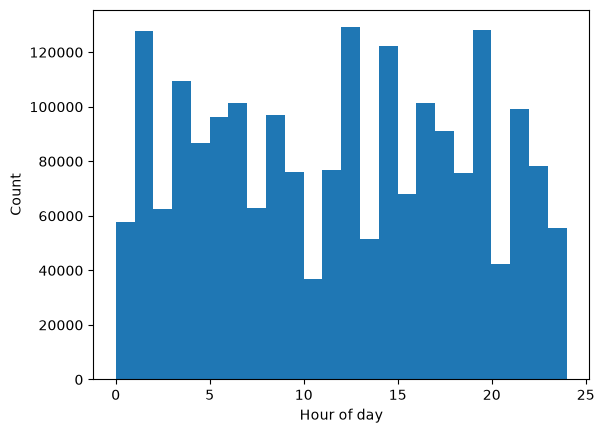

In [3]:
import matplotlib.pyplot as plt
df_time = pd.to_datetime(df_good["time"])
hour = (
    df_time.dt.hour
    + df_time.dt.minute / 60
    + df_time.dt.second / 3600
)

plt.hist(hour, bins=24)
plt.xlabel("Hour of day")
plt.ylabel("Count")
plt.show()

## A reusable function to bin CHLA from ERDDAP

The ERDDAP access and daily-binning logic is in `src/chla_z_build.py`, shared with the command-line build (`datasets/chla_z/build.py`):

- `ooi_month_unit(dataset_id, month)` downloads one dataset-month as CSV to `_temp_data/ooi_raw/<dataset_id>/<YYYY-MM>.csv.gz`. It retries with backoff on dropped connections and server errors, and writes an `.empty` marker only when ERDDAP answers "no matching results". Fetching by month means a failure costs one month, not a whole multi-year dataset, and a rerun skips what is already there.
- `ooi_daily_profiles(df, dataset_id, chl_var, description)` turns raw rows into **daily mean CHLA** in 10 m depth bins (depth = -z, A <= depth < B), using QC `qc_agg == 1`. The time is the mean time of that day's good samples, not midnight. Nine fixed-depth datasets that publish z = 0 use the known sensor depth (`DEPTH_OVERRIDE_M`).
- `ooi_dataset_unit(dataset_id)` bins all months of one dataset and saves `_temp_data/ooi_daily/<dataset_id>.parquet`.

In [4]:
import sys
if "../../../src" not in sys.path:
    sys.path.insert(0, "../../../src")
import chla_z_build as b
from chla_z_build import ooi_daily_profiles, DEPTH_OVERRIDE_M
DEPTH_OVERRIDE_M

{'ooi-gi01sumo-rid16-02-flortd000': 12.0,
 'ooi-gi03flmb-ris01-05-flortd000': 25.0,
 'ooi-gi03flma-ris01-05-flortd000': 26.0,
 'ooi-gi01sumo-rii11-02-flordg031': 40.0,
 'ooi-gi01sumo-rii11-02-flordg032': 80.0,
 'ooi-gi01sumo-rii11-02-flordg033': 130.0,
 'ooi-gp03flma-ris01-05-flortd000': 28.0,
 'ooi-gp03flmb-ris01-05-flortd000': 30.0,
 'ooi-rs03axps-pc03a-4c-flordd303': 187.0}

## Define OOI platforms of interest

Each key in `OOI_DATASETS` (`src/chla_z_ooi_datasets.py`) is an ERDDAP `dataset_id` on `https://erddap.dataexplorer.oceanobservatories.org/erddap`, and each value is a human-readable description of the mooring or profiler (location and instrument type, e.g., 3-wavelength fluorometer).

Three datasets are excluded for reasons that do not depend on dates (`b.OOI_EXCLUDE`). The 2025 version also skipped 31 datasets as "no data in time range"; with the range extended to October 2026 they are queried again. Months outside a dataset's ERDDAP `time_coverage` are not requested.

In [5]:
from chla_z_ooi_datasets import OOI_DATASETS
ooi_dict = b.ooi_datasets()   # OOI_DATASETS minus b.OOI_EXCLUDE
print(len(OOI_DATASETS), "listed,", len(ooi_dict), "used")
b.OOI_EXCLUDE

64 listed, 61 used


{'ooi-ce02shsp-sp002-07-flortj000': 'no qc_agg variable',
 'ooi-rs01sbps-pc01a-4c-flordd103': 'no qc_agg variable',
 'ooi-gp02hypm-wfp03-01-flordl000': '2000 m and deeper'}

## Read data from ERDDAP and save per-platform daily CHLA files

This loops over every dataset and every month from 2024-03 to 2026-10 that the dataset covers. Each dataset-month is saved, so the loop can be stopped and rerun. The command-line equivalent runs three downloads at a time:

```
cd datasets/chla_z
python build.py ooi-fetch --workers 3
python build.py ooi
```

In [6]:
%%script false --no-raise-error
# comment the line above to run; it downloads ~700 dataset-months
for dataset_id in ooi_dict:
    for month in b.ooi_months_for(dataset_id):
        print(b.ooi_month_unit(dataset_id, month))
    print(b.ooi_dataset_unit(dataset_id))

## Inspect a single saved daily CHLA file

After running the ERDDAP download step, inspect one parquet file to verify:

- CHLA depth-bin columns are present and look reasonable.
- Time, latitude, and longitude are as expected for the platform.


In [7]:
# Examine the file
import pandas as pd
dataset_id = "ooi-ce01issp-sp001-08-flortj000"
df = pd.read_parquet(b.OOI_DAILY / f"{dataset_id}.parquet")
df.head()

,profile_id,time,lat,lon,CHLA_0_10,CHLA_10_20,CHLA_20_30,CHLA_30_40,CHLA_40_50,CHLA_50_60,...,CHLA_110_120,CHLA_120_130,CHLA_130_140,CHLA_140_150,CHLA_150_160,CHLA_160_170,CHLA_170_180,CHLA_180_190,CHLA_190_200,description
0,ooi-ce01issp-sp001-08-flortj000_20240411,2024-04-11 06:49:46.956521+00:00,44.65845,-124.0979,1.248099,1.369662,1.073702,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Coastal Endurance: Oregon Inshore Surface Pier...
1,ooi-ce01issp-sp001-08-flortj000_20240412,2024-04-12 07:22:49.090909+00:00,44.65845,-124.0979,1.285849,1.286291,0.988821,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Coastal Endurance: Oregon Inshore Surface Pier...
2,ooi-ce01issp-sp001-08-flortj000_20240417,2024-04-17 20:04:06+00:00,44.65845,-124.0979,0.384099,0.510783,0.457698,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Coastal Endurance: Oregon Inshore Surface Pier...
3,ooi-ce01issp-sp001-08-flortj000_20240418,2024-04-18 13:36:35.384615+00:00,44.65845,-124.0979,0.330928,0.311356,0.278780,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Coastal Endurance: Oregon Inshore Surface Pier...
4,ooi-ce01issp-sp001-08-flortj000_20240419,2024-04-19 08:04:30+00:00,44.65845,-124.0979,0.384770,0.366793,0.327334,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Coastal Endurance: Oregon Inshore Surface Pier...


## Merge all platforms into a single OOI CHLA dataset

`chla_z_tables.write_ooi_profiles()` (using `chla_z_build.ooi_combine()`):

- Reads all per-dataset daily files from `_temp_data/ooi_daily/`; every file already has all CHLA depth-bin columns (`CHLA_0_10`, …, `CHLA_190_200`).
- `profile_id` is `datasetID_YYYYMMDD`, one row per **platform × day**; the code checks that it is unique.
- Applies the **Sauzède fluorescence:chla correction** in place (`chla_corrected = chla_fluor / ratio`), keeping a `chla_ratio` column so the raw values can be recovered (`raw = adj * ratio`). Sites with no LUT coverage are left uncorrected (ratio = 1); in this rebuild every site had LUT coverage. Data attribution: Sauzède, R. (2025), SEANOE, doi:10.17882/105732 (CC-BY-4.0).
- Saves `data/CHLA_ooi_profiles.parquet` with metadata.

In [8]:
import chla_z_tables as t
combined = t.write_ooi_profiles()
combined.head()

2026-11-22 13:28:57 wrote CHLA_ooi_profiles.parquet: 13664 rows, 26 columns


,profile_id,time,lat,lon,CHLA_0_10,CHLA_10_20,CHLA_20_30,CHLA_30_40,CHLA_40_50,CHLA_50_60,...,CHLA_120_130,CHLA_130_140,CHLA_140_150,CHLA_150_160,CHLA_160_170,CHLA_170_180,CHLA_180_190,CHLA_190_200,description,chla_ratio
0,ooi-rs01sbps-sf01a-3a-flortd101_20240301,2024-03-01 11:37:37.458441+00:00,44.528951,-125.389669,1.047216,1.049328,1.068695,1.114165,1.098140,1.069141,...,0.063592,0.061078,0.058934,0.058496,0.056321,0.055654,0.057790,NaN,Regional Cabled Array: Oregon Slope Base Shall...,0.767164
1,ooi-rs03axps-sf03a-3a-flortd301_20240301,2024-03-01 11:40:22.805429+00:00,45.830470,-129.753198,NaN,0.769192,0.840601,0.906100,0.923122,0.894304,...,0.018871,0.015626,0.015010,0.015437,0.013908,0.017255,0.019532,NaN,Regional Cabled Array: Axial Base Shallow Prof...,1.342187
2,ooi-gi01sumo-sbd12-02-flortd000_20240301,2024-03-01 11:40:44.831460+00:00,59.935350,-39.467850,0.074042,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Global Irminger Sea: Apex Surface Mooring: Sur...,2.446314
3,ooi-gp03flma-ris01-05-flortd000_20240301,2024-03-01 11:45:00+00:00,49.977563,-144.245227,NaN,NaN,0.772145,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Global Station Papa: Flanking Subsurface Moori...,1.025228
4,ooi-gp03flmb-ris01-05-flortd000_20240301,2024-03-01 11:45:00+00:00,50.329570,-144.398637,NaN,NaN,NaN,0.511889,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Global Station Papa: Flanking Subsurface Moori...,1.025228


## Select a random daily profile and plot CHLA vs depth

Finally, we:

- Load the merged Endurance CHLA dataset.
- Identify `profile_id` values with at least a minimum number of non-NaN CHLA depth bins.
- Randomly select one valid daily profile.
- Retrieve the platform description for context.
- Convert CHLA depth-bin columns into depth midpoints and plot **CHLA vs depth** for the selected daily profile.


Using profile_id: ooi-cp14nepm-wfp01-04-flortk000_20240626 with 18 valid CHLA bins


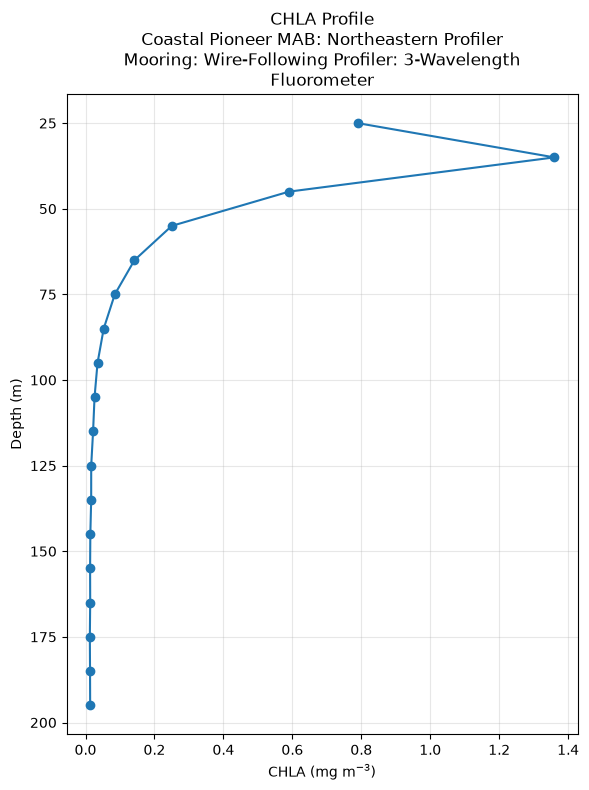

In [9]:
# Create a plot
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import textwrap

# ---- 1. Load combined dataset ----
combined_path = b.DATA_DIR / "CHLA_ooi_profiles.parquet"
df = pd.read_parquet(combined_path)

# Ensure time is datetime (not strictly needed for the plot, but nice to have)
df["time"] = pd.to_datetime(df["time"])

# ---- 2. Identify CHLA columns and pick a good profile ----
chla_cols = [c for c in df.columns if c.startswith("CHLA_")]

if not chla_cols:
    raise ValueError("No CHLA_ columns found in the dataframe.")

# Count how many non-NaN CHLA values each profile_id has (per row)
# (Assumes one row per profile_id; if multiple, takes the max across rows.)
counts = (
    df.groupby("profile_id")[chla_cols]
      .apply(lambda x: x.notna().sum(axis=1).max())
)

# Get a profile_id with at least 10 valid CHLA bins
valid_profiles = counts[counts >= 10]
if valid_profiles.empty:
    raise ValueError("No profile_id found with at least 10 non-NaN CHLA bins.")

rand_row = valid_profiles.sample(1, random_state=None)  # set an int seed if you want reproducible

profile_id = rand_row.index[0]
n_bins = rand_row.iloc[0]

print(f"Using profile_id: {profile_id} with {n_bins} valid CHLA bins")

# Get Description
desc = df.loc[df["profile_id"] == profile_id, "description"].iloc[0]

# ---- 3. Extract that profile ----
sub = df[df["profile_id"] == profile_id].copy()

# If there somehow are multiple rows for this profile, average them
if len(sub) > 1:
    sub = sub.groupby("profile_id")[chla_cols].mean().reset_index()
else:
    sub = sub.reset_index(drop=True)

# Take the first (or only) row of CHLA values
chla_vals = sub[chla_cols].iloc[0].values

# ---- 4. Build depth midpoints from CHLA_0_10 style column names ----
# CHLA_0_10 -> lower edge = 0 -> midpoint = 5
depths = []
for col in chla_cols:
    # col format assumed: "CHLA_<z1>_<z2>"
    parts = col.split("_")
    if len(parts) < 3:
        raise ValueError(f"Unexpected CHLA column format: {col}")
    z1 = int(parts[1])
    z_mid = z1 + 5  # 10 m bin midpoint
    depths.append(z_mid)

depths = np.array(depths)
chla_vals = np.array(chla_vals, dtype=float)

# Sort by depth (just in case columns are out of order)
order = np.argsort(depths)
depths = depths[order]
chla_vals = chla_vals[order]

# Mask out NaNs so the plot doesn't connect them
valid = ~np.isnan(chla_vals)
depths_valid = depths[valid]
chla_valid = chla_vals[valid]

# ---- 5. Plot CHLA vs depth ----
plt.figure(figsize=(6, 8))
plt.plot(chla_valid, depths_valid, marker="o")

plt.gca().invert_yaxis()  # surface at top
plt.xlabel("CHLA (mg m$^{-3}$)")
plt.ylabel("Depth (m)")
wrapped_desc = textwrap.fill(desc, width=50)  # adjust width to taste
plt.title(f"CHLA Profile\n{wrapped_desc}")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Match ups to PACE

The OOI and Argo profiles are matched to PACE together, one pass over each PACE granule, in `argo-matchups.ipynb` (or `python build.py pace --product Rrs|chlor_a|Kd` then `python build.py pace-merge`). That writes `data/CHLA_ooi_profiles_plus_PACE.parquet`. The rules: PACE V3.2 daily 4 km AOP (Rrs), BGC (chlor_a) and KD (Kd_490); a profile matches a file when its time is within 24 h after the file's `time_coverage_start`; nearest 4 km grid cell; standard files are preferred over NRT, then the file whose time window centre is closest. Choosing one file per profile also removes the duplicate rows of the 2025 table, where OOI times stamped at midnight fell into two granule windows.

In [10]:
# Check the merged OOI + PACE table and its metadata
import pyarrow.parquet as pq
out_path = b.DATA_DIR / "CHLA_ooi_profiles_plus_PACE.parquet"
df = pd.read_parquet(out_path)
assert not df["profile_id"].duplicated().any()
print(df.shape)
{k.decode(): v.decode()[:120] for k, v in pq.read_schema(out_path).metadata.items() if k != b"pandas"}

(13102, 205)


{'title': 'OOI CHLA profile metrics (0 to 200 m, 10 m bins) with PACE Rrs, chlor_a and Kd_490 matchups',
 'source': 'NSF Ocean Observatories Initiative. (2014). Data Explorer ERDDAP https://erddap.dataexplorer.oceanobservatories.org/erdd',
 'description': 'OOI fluorometer CHLA from profilers and fixed-depth instruments, 2024-03-01 to 2026-10-31, from the OOI Data Explorer ER',
 'creator': 'Eli Holmes / NOAA https://orcid.org/0000-0001-9128-8393',
 'profile_id_definition': "profile_id = ERDDAP dataset_id + '_' + YYYYMMDD (UTC day).",
 'time_definition': 'Mean time (UTC) of the QC-passing observations in that day. Note: for moorings that sample all day this is close to 12:0',
 'lat_definition': 'lat in the ERDDAP dataset (first value of the day). OOI platforms are fixed.',
 'lon_definition': 'lon in the ERDDAP dataset (first value of the day).',
 'CHLA_A_B_definition': 'Daily mean of QC-passing CHLA (qc_agg = 1) with A <= depth < B, where depth = -z in m, divided by chla_ratio (see CHLA_

## Summary

This completes the preparation of our OOI + PACE matchups dataset. Now that we have the data we can use is to train a model to predict CHLA using OOI CHLA data and compare to PACE chlor_a from Rrs ratios.

The OOI and PACE (satellite-derived) chlorophyll-a estimates will not match. One is based on reflectance from the water column while the other is in-situ reflectance. But they are correlated. This plot shows a oft observed pattern where the satellite derived estimate is higher when surface CHLA is lower. Conversely, the in-situ surface measurement is a bit higher when CHLA is higher. But note that we don't have many in-situ measurements over 1 (on log10 scale) so about 10 on the non-log scale. According to the PACE measurements we do have values above 1.4 (bloom), but the OOI measurements tend to be lower in those cases.



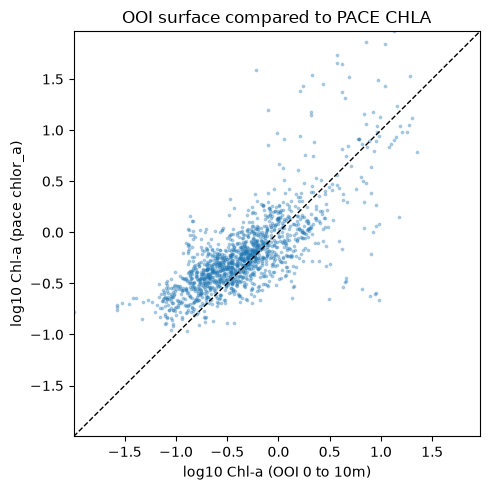

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_squared_error

df = pd.read_parquet(b.DATA_DIR / "CHLA_ooi_profiles_plus_PACE.parquet")
df_clean = df.dropna(subset=["CHLA_0_10"])

# Take logs (natural log; use np.log10 if you prefer log10)
y_ooi = df_clean["CHLA_0_10"].values
y_pace = df_clean["pace_chlor_a"].values

# Mask: positive & finite in both
mask = (
    np.isfinite(y_ooi) &
    np.isfinite(y_pace) &
    (y_ooi > 0) &
    (y_pace > 0)
)

y_ooi = y_ooi[mask]
y_pace = y_pace[mask]

y_ooi = np.log10(y_ooi)
y_pace = np.log10(y_pace)

# Scatter plot
plt.figure(figsize=(5, 5))
plt.scatter(y_ooi, y_pace, s=3, alpha=0.3)

# 1:1 line
lims = [
    min(y_ooi.min(), y_pace.min()),
    max(y_ooi.max(), y_pace.max())
]
plt.plot(lims, lims, "k--", linewidth=1)
plt.xlim(lims)
plt.ylim(lims)

plt.xlabel("log10 Chl-a (OOI 0 to 10m)")
plt.ylabel("log10 Chl-a (pace chlor_a)")
plt.title("OOI surface compared to PACE CHLA")
plt.tight_layout()
plt.show()